# CADT 实验结果汇总

In [41]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

%matplotlib inline
sns.set_style('whitegrid')

In [42]:
def parse_results_file(filepath):
    '''解析单个 results.txt 文件，提取关键指标'''
    with open(filepath, 'r') as f:
        content = f.read()

    result = {}

    timestamp_match = re.search(r'Timestamp: (\d{8}_\d{6})', content)
    if timestamp_match:
        result['timestamp'] = timestamp_match.group(1)

    split_mode_match = re.search(r'Split Mode: (\w+)', content)
    if split_mode_match:
        result['split_mode'] = split_mode_match.group(1)

    target_subject_match = re.search(r'Target Subject: (\d+)', content)
    if target_subject_match:
        result['target_subject'] = int(target_subject_match.group(1))
    else:
        result['target_subject'] = 'all'

    best_epoch_match = re.search(r'Best Epoch: (\d+)', content)
    if best_epoch_match:
        result['best_epoch'] = int(best_epoch_match.group(1))

    n_source_domains_match = re.search(r'Number of Source Domains: (\d+)', content)
    if n_source_domains_match:
        result['n_source_domains'] = int(n_source_domains_match.group(1))

    val_mse_match = re.search(r'Val MSE: ([\d.]+)', content)
    if val_mse_match:
        result['val_mse'] = float(val_mse_match.group(1))

    val_mae_match = re.search(r'Val MAE: ([\d.]+)', content)
    if val_mae_match:
        result['val_mae'] = float(val_mae_match.group(1))

    val_rmse_match = re.search(r'Val RMSE: ([\d.]+)', content)
    if val_rmse_match:
        result['val_rmse'] = float(val_rmse_match.group(1))

    val_r2_match = re.search(r'Val R2: ([\d.-]+)', content)
    if val_r2_match:
        result['val_r2'] = float(val_r2_match.group(1))

    val_avg_r2_match = re.search(r'Val Avg R2 \(per-dim\): ([\d.-]+)', content)
    if val_avg_r2_match:
        result['val_avg_r2'] = float(val_avg_r2_match.group(1))

    val_pearson_match = re.search(r'Val Pearson: ([\d.-]+)', content)
    if val_pearson_match:
        result['val_pearson'] = float(val_pearson_match.group(1))

    val_spearman_match = re.search(r'Val Spearman: ([\d.-]+)', content)
    if val_spearman_match:
        result['val_spearman'] = float(val_spearman_match.group(1))

    test_mse_match = re.search(r'Test MSE: ([\d.]+)', content)
    if test_mse_match:
        result['test_mse'] = float(test_mse_match.group(1))

    test_mae_match = re.search(r'Test MAE: ([\d.]+)', content)
    if test_mae_match:
        result['test_mae'] = float(test_mae_match.group(1))

    test_rmse_match = re.search(r'Test RMSE: ([\d.]+)', content)
    if test_rmse_match:
        result['test_rmse'] = float(test_rmse_match.group(1))

    test_r2_match = re.search(r'Test R2: ([\d.-]+)', content)
    if test_r2_match:
        result['test_r2'] = float(test_r2_match.group(1))

    test_avg_r2_match = re.search(r'Test Avg R2 \(per-dim\): ([\d.-]+)', content)
    if test_avg_r2_match:
        result['test_avg_r2'] = float(test_avg_r2_match.group(1))

    test_pearson_match = re.search(r'Test Pearson: ([\d.-]+)', content)
    if test_pearson_match:
        result['test_pearson'] = float(test_pearson_match.group(1))

    test_spearman_match = re.search(r'Test Spearman: ([\d.-]+)', content)
    if test_spearman_match:
        result['test_spearman'] = float(test_spearman_match.group(1))

    per_emotion_section = re.search(r'--- Per-Emotion Metrics ---.*?(?=\n\n|\nModel Saved:|$)', content, re.DOTALL)
    if per_emotion_section:
        emotion_lines = per_emotion_section.group(0).split('\n')[2:]
        emotion_metrics = {}
        for line in emotion_lines:
            if line.strip() and not line.strip().startswith('---') and not line.strip().startswith('Average'):
                parts = re.split(r'\s+', line.strip())
                if len(parts) >= 6:
                    # 新格式: Emotion MSE MAE R2 Pearson Spearman
                    emotion = parts[0]
                    emotion_metrics[emotion] = {}
                    emotion_metrics[emotion]['mse'] = float(parts[1])
                    emotion_metrics[emotion]['mae'] = float(parts[2])
                    emotion_metrics[emotion]['r2'] = float(parts[3])
                    emotion_metrics[emotion]['pearson'] = float(parts[4])
                    emotion_metrics[emotion]['spearman'] = float(parts[5])
                elif len(parts) >= 5:
                    # 兼容旧格式: Emotion MSE MAE Pearson Spearman
                    emotion = parts[0]
                    emotion_metrics[emotion] = {}
                    emotion_metrics[emotion]['mse'] = float(parts[1])
                    emotion_metrics[emotion]['mae'] = float(parts[2])
                    emotion_metrics[emotion]['pearson'] = float(parts[3])
                    emotion_metrics[emotion]['spearman'] = float(parts[4])
        result['per_emotion'] = emotion_metrics

    return result

In [43]:
def parse_params_file(filepath):
    '''解析 params.txt 文件，提取训练参数'''
    with open(filepath, 'r') as f:
        content = f.read()

    params = {}
    params_match = re.findall(r'(\w+): ([\d.]+)', content)
    for key, value in params_match:
        try:
            params[key] = int(value)
        except ValueError:
            try:
                params[key] = float(value)
            except ValueError:
                params[key] = value
    return params

In [44]:
def load_all_experiments(results_dir='/root/zjm/cadt/results4'):
    '''加载 results_dir 下所有实验结果'''
    experiments = []
    for entry in os.listdir(results_dir):
        entry_path = os.path.join(results_dir, entry)
        if os.path.isdir(entry_path) and 'emotion' in entry:
            results_file = os.path.join(entry_path, 'results.txt')
            params_file = os.path.join(entry_path, 'params.txt')
            if os.path.exists(results_file):
                result = parse_results_file(results_file)
                result['directory'] = entry
                if os.path.exists(params_file):
                    params = parse_params_file(params_file)
                    result.update(params)
                experiments.append(result)
    return experiments

In [45]:
# 加载所有实验
experiments = load_all_experiments()
print(f'共加载 {len(experiments)} 个实验')

# 转换为 DataFrame
df = pd.DataFrame(experiments)
df['datetime'] = pd.to_datetime(df['timestamp'], format='%Y%m%d_%H%M%S')
df = df.sort_values('datetime').reset_index(drop=True)

# 评价指标列表
metrics = ['val_mse', 'val_mae', 'val_rmse', 'val_r2', 'val_avg_r2', 'val_pearson', 'val_spearman',
           'test_mse', 'test_mae', 'test_rmse', 'test_r2', 'test_avg_r2', 'test_pearson', 'test_spearman']

# 显示基本信息
df[['timestamp', 'split_mode', 'target_subject', 'best_epoch', 'n_source_domains', 'val_mse', 'val_r2', 'val_avg_r2', 'test_mse', 'test_r2', 'test_avg_r2']]

共加载 90 个实验


,timestamp,split_mode,target_subject,best_epoch,n_source_domains,val_mse,val_r2,val_avg_r2,test_mse,test_r2,test_avg_r2
0,20260724_041801,cross_subject,all,327,9,0.974905,0.198304,-0.049200,0.699435,0.108430,-0.168933
1,20260724_061444,cross_day,1,130,6,0.711184,0.235313,-0.206413,0.910800,-0.007007,-0.191097
2,20260724_071121,within_subject_day,all,0,150,0.795973,0.239573,-0.003838,0.886409,0.185150,-0.028494
3,20260724_161802,cross_day,2,270,6,0.925640,0.178917,-0.490663,0.514444,0.396295,-0.328744
4,20260725_020320,cross_day,3,268,6,1.148709,0.202260,-0.295779,1.174133,0.159327,-0.240713
...,...,...,...,...,...,...,...,...,...,...,...
85,20260729_060038,cross_day,14,236,6,0.376782,0.352772,-0.047804,0.296335,0.474706,-0.098187
86,20260729_060353,cross_day,14,110,6,0.383881,0.340578,-0.068098,0.268445,0.524145,-0.073839
87,20260729_061927,cross_day,15,174,6,0.348379,-0.069399,-0.330127,0.446719,-0.055923,-0.315163
88,20260729_062524,cross_day,15,244,6,0.339161,-0.041102,-0.333730,0.451797,-0.067925,-0.343330


## 多Seed实验汇总（均值±标准差）

In [46]:
def format_mean_std(mean, std, decimals=4):
    '''格式化均值±标准差'''
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"

# 按 split_mode 和 target_subject 分组
grouped = df.groupby(['split_mode', 'target_subject'])

# 计算均值、标准差和统计显著性
summary_list = []

for (split_mode, subject), group in grouped:
    row = {
        'split_mode': split_mode,
        'target_subject': subject,
        'n_seeds': len(group),
        'timestamps': ', '.join(group['timestamp'].tolist())
    }
    
    for metric in metrics:
        if metric in group.columns:
            values = group[metric].dropna().values
            if len(values) > 0:
                row[f'{metric}_mean'] = np.mean(values)
                row[f'{metric}_std'] = np.std(values, ddof=1)
                row[f'{metric}_mean_std'] = format_mean_std(np.mean(values), np.std(values, ddof=1))
                
                # 计算95%置信区间
                if len(values) >= 2:
                    ci_low, ci_high = stats.t.interval(0.95, len(values)-1, loc=np.mean(values), scale=stats.sem(values))
                    row[f'{metric}_ci_95'] = f"[{ci_low:.4f}, {ci_high:.4f}]"
                
                # 不同seed间差异的显著性检验
                if len(values) >= 2:
                    # 使用单样本t检验: 检验seed均值是否显著偏离0（零假设）
                    # 注意: 这里不是直接比较seed，而是检验结果是否显著非零
                    if len(values) >= 2 and np.std(values, ddof=1) > 0:
                        t_stat, p_one = stats.ttest_1samp(values, 0)
                        row[f'{metric}_t_stat'] = t_stat
                        row[f'{metric}_p_value'] = p_one
                        row[f'{metric}_significant'] = '**' if p_one < 0.01 else '*' if p_one < 0.05 else 'ns'
                    # Levene方差齐性检验需要至少两组独立数据
                    # 同一受试者内无法做Levene检验（只有一组seed数据）
                    # 如需Levene检验，请使用跨受试者对比的方差分析
    
    summary_list.append(row)

summary_df = pd.DataFrame(summary_list)

# 显示汇总表格 - 分为验证集和测试集两个表格
val_metrics = [m for m in metrics if m.startswith('val_')]
test_metrics = [m for m in metrics if m.startswith('test_')]

print('=' * 80)
print('验证集结果 (Validation Set)')
print('=' * 80)
val_cols = ['split_mode', 'target_subject', 'n_seeds'] + [f'{m}_mean_std' for m in val_metrics]
display(summary_df[val_cols])

print('=' * 80)
print('测试集结果 (Test Set)')
print('=' * 80)
test_cols = ['split_mode', 'target_subject', 'n_seeds'] + [f'{m}_mean_std' for m in test_metrics]
display(summary_df[test_cols])

验证集结果 (Validation Set)


,split_mode,target_subject,n_seeds,val_mse_mean_std,val_mae_mean_std,val_rmse_mean_std,val_r2_mean_std,val_avg_r2_mean_std,val_pearson_mean_std,val_spearman_mean_std
0,cross_day,1,5,0.7025 ± 0.0080,0.6274 ± 0.0090,0.8381 ± 0.0048,0.2446 ± 0.0086,-0.1712 ± 0.0485,-0.0102 ± 0.0922,0.0053 ± 0.0704
1,cross_day,2,5,0.9275 ± 0.0076,0.5917 ± 0.0057,0.9631 ± 0.0039,0.1773 ± 0.0067,-0.2782 ± 0.2068,0.0387 ± 0.0523,0.0359 ± 0.0492
2,cross_day,3,5,1.2321 ± 0.0725,0.8341 ± 0.0231,1.1096 ± 0.0325,0.1444 ± 0.0504,-0.2131 ± 0.0627,0.0305 ± 0.0261,0.0461 ± 0.0447
3,cross_day,4,5,0.8860 ± 0.0176,0.7250 ± 0.0052,0.9413 ± 0.0094,0.1261 ± 0.0174,-0.1907 ± 0.0238,0.1243 ± 0.0553,0.1290 ± 0.0534
4,cross_day,5,5,0.7267 ± 0.0421,0.6499 ± 0.0169,0.8522 ± 0.0249,0.3246 ± 0.0391,-0.1595 ± 0.0675,-0.0076 ± 0.1550,-0.0157 ± 0.1364
5,cross_day,6,5,0.7589 ± 0.0482,0.6983 ± 0.0137,0.8708 ± 0.0275,0.3015 ± 0.0443,-0.5953 ± 0.0982,-0.0287 ± 0.0477,-0.0358 ± 0.0393
6,cross_day,7,5,0.3075 ± 0.0207,0.3098 ± 0.0085,0.5543 ± 0.0186,0.1263 ± 0.0588,-0.3073 ± 0.3374,0.0109 ± 0.0570,0.0057 ± 0.0626
7,cross_day,8,5,0.7304 ± 0.0148,0.6705 ± 0.0054,0.8546 ± 0.0087,0.2023 ± 0.0162,-0.2759 ± 0.0269,-0.0423 ± 0.0441,-0.0482 ± 0.0399
8,cross_day,9,5,0.7100 ± 0.0545,0.6756 ± 0.0287,0.8421 ± 0.0325,-0.2919 ± 0.0992,-0.6748 ± 0.2629,-0.0463 ± 0.0358,-0.0483 ± 0.0341
9,cross_day,10,5,0.3840 ± 0.0061,0.4959 ± 0.0036,0.6197 ± 0.0049,0.5349 ± 0.0074,-0.0785 ± 0.0431,0.0297 ± 0.0403,0.0389 ± 0.0289


测试集结果 (Test Set)


,split_mode,target_subject,n_seeds,test_mse_mean_std,test_mae_mean_std,test_rmse_mean_std,test_r2_mean_std,test_avg_r2_mean_std,test_pearson_mean_std,test_spearman_mean_std
0,cross_day,1,5,0.9542 ± 0.0838,0.7317 ± 0.0410,0.9761 ± 0.0425,-0.0550 ± 0.0926,-0.5003 ± 0.3184,0.0390 ± 0.0785,0.0440 ± 0.0749
1,cross_day,2,5,0.5077 ± 0.0103,0.4360 ± 0.0115,0.7125 ± 0.0072,0.4043 ± 0.0121,-0.5431 ± 0.1895,0.0194 ± 0.0238,0.0186 ± 0.0219
2,cross_day,3,5,1.3575 ± 0.1469,0.8911 ± 0.0398,1.1637 ± 0.0635,0.0280 ± 0.1052,-0.4634 ± 0.1649,-0.0110 ± 0.1351,-0.0309 ± 0.1365
3,cross_day,4,5,0.6578 ± 0.0261,0.6392 ± 0.0121,0.8109 ± 0.0160,0.2028 ± 0.0317,-0.3282 ± 0.0235,-0.2059 ± 0.0507,-0.2114 ± 0.0591
4,cross_day,5,5,0.7582 ± 0.0115,0.6856 ± 0.0091,0.8707 ± 0.0066,0.2924 ± 0.0107,-0.2000 ± 0.0300,0.0337 ± 0.0379,0.0364 ± 0.0295
5,cross_day,6,5,0.6641 ± 0.0177,0.6284 ± 0.0054,0.8149 ± 0.0109,0.5423 ± 0.0122,-0.1760 ± 0.1320,0.0916 ± 0.0607,0.0954 ± 0.0663
6,cross_day,7,5,0.2375 ± 0.0055,0.2794 ± 0.0111,0.4873 ± 0.0056,0.1859 ± 0.0189,-0.2178 ± 0.2675,0.0180 ± 0.0685,0.0203 ± 0.0667
7,cross_day,8,5,1.0322 ± 0.0376,0.7712 ± 0.0137,1.0159 ± 0.0185,-0.2052 ± 0.0439,-0.5835 ± 0.2045,0.1715 ± 0.0456,0.1584 ± 0.0523
8,cross_day,9,5,0.8060 ± 0.0561,0.7651 ± 0.0387,0.8973 ± 0.0312,-0.0002 ± 0.0696,-0.5366 ± 0.2379,0.0194 ± 0.0542,0.0159 ± 0.0504
9,cross_day,10,5,0.7659 ± 0.0148,0.7002 ± 0.0065,0.8752 ± 0.0085,0.2230 ± 0.0150,-0.1089 ± 0.0643,0.0595 ± 0.1637,0.0655 ± 0.1648


## 统计显著性检验

### 1. 不同受试者的差异显著性（ANOVA）
- 零假设 H₀ ：所有受试者的指标均值相同（μ₁ = μ₂ = ... = μₖ）
- 备择假设 H₁ ：至少有一个受试者的均值与其他受试者不同

In [47]:
def anova_test(data, group_col, value_col):
    '''单因素方差分析'''
    groups = []
    for name, group in data.groupby(group_col):
        groups.append(group[value_col].dropna().values)
    
    if len(groups) >= 2:
        f_stat, p_value = stats.f_oneway(*groups)
        return f_stat, p_value
    return np.nan, np.nan

# 对每个指标进行ANOVA检验
anova_results = []

# 只分析 cross_day 模式
cross_day_df = df[df['split_mode'] == 'cross_day'].copy()

for metric in metrics:
    if metric in cross_day_df.columns:
        # 按target_subject分组，每个subject作为一组
        f_stat, p_value = anova_test(cross_day_df, 'target_subject', metric)
        anova_results.append({
            'metric': metric,
            'f_stat': f_stat,
            'p_value': p_value,
            'significant': '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
            })

anova_df = pd.DataFrame(anova_results)
anova_df.style.format({
    'f_stat': '{:.4f}',
    'p_value': '{:.6f}'
}).set_table_styles([{
    'selector': 'th',
    'props': [('font-size', '11px'), ('text-align', 'center')]
}, {
    'selector': 'td',
    'props': [('font-size', '11px'), ('text-align', 'center')]
}])

,metric,f_stat,p_value,significant
0,val_mse,344.1987,0.000000,**
1,val_mae,593.7125,0.000000,**
2,val_rmse,426.2430,0.000000,**
3,val_r2,142.8248,0.000000,**
4,val_avg_r2,8.8603,0.000000,**
5,val_pearson,4.5637,0.000009,**
6,val_spearman,5.2628,0.000001,**
7,test_mse,170.2874,0.000000,**
8,test_mae,356.8467,0.000000,**
9,test_rmse,255.1964,0.000000,**


### 2. 事后检验：Tukey HSD 检验

当ANOVA结果显著时（p < 0.05），使用Tukey HSD检验进行两两比较，找出哪些受试者之间存在显著差异(reject=True)。


=== val_r2 - Tukey HSD 检验 ===
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     1     10   0.2902    0.0  0.2063  0.3742   True
     1     11   0.2445    0.0  0.1606  0.3285   True
     1     12   0.1444    0.0  0.0605  0.2283   True
     1     13    0.021 0.9999 -0.0629   0.105  False
     1     14   0.1009 0.0057   0.017  0.1848   True
     1     15  -0.2888    0.0 -0.3727 -0.2048   True
     1      2  -0.0674 0.2622 -0.1513  0.0165  False
     1      3  -0.1003 0.0062 -0.1842 -0.0164   True
     1      4  -0.1185 0.0004 -0.2024 -0.0346   True
     1      5     0.08  0.078  -0.004  0.1639  False
     1      6   0.0569 0.5429  -0.027  0.1408  False
     1      7  -0.1183 0.0004 -0.2022 -0.0344   True
     1      8  -0.0423 0.9085 -0.1262  0.0416  False
     1      9  -0.5365    0.0 -0.6204 -0.4526   True
     1    all  -0.0129    1.0 -0.0969   0.071  False
    10     11  

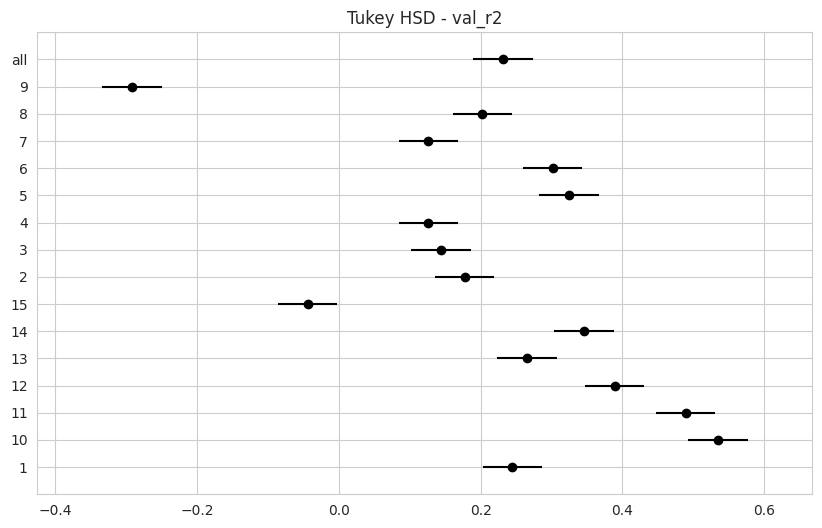


=== test_r2 - Tukey HSD 检验 ===
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     1     10   0.2781    0.0  0.1663  0.3899   True
     1     11   0.2464    0.0  0.1346  0.3582   True
     1     12   0.1412 0.0028  0.0294   0.253   True
     1     13   0.2514    0.0  0.1396  0.3632   True
     1     14   0.5559    0.0  0.4441  0.6677   True
     1     15  -0.0181    1.0 -0.1299  0.0937  False
     1      2   0.4593    0.0  0.3475  0.5711   True
     1      3   0.0831 0.3847 -0.0287  0.1949  False
     1      4   0.2578    0.0  0.1461  0.3696   True
     1      5   0.3475    0.0  0.2357  0.4592   True
     1      6   0.5973    0.0  0.4855  0.7091   True
     1      7   0.2409    0.0  0.1291  0.3527   True
     1      8  -0.1502  0.001  -0.262 -0.0384   True
     1      9   0.0548  0.925  -0.057  0.1666  False
     1    all   0.2362    0.0  0.1244   0.348   True
    10     11 

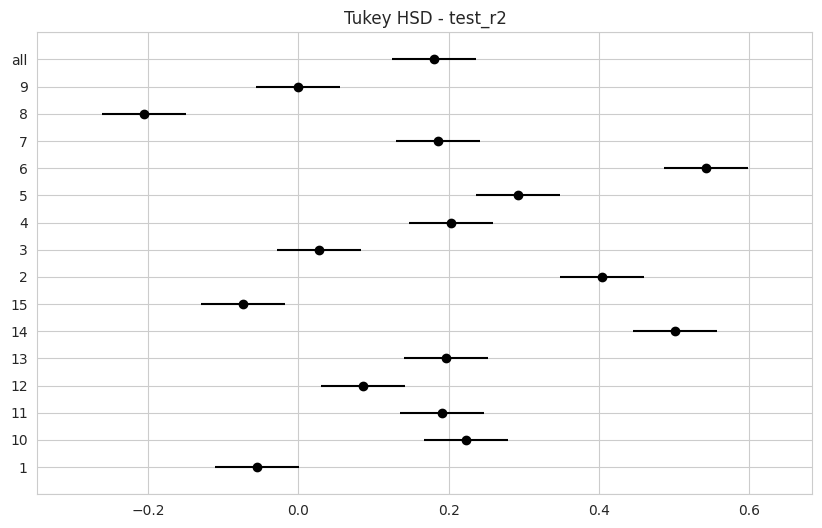


=== val_mse - Tukey HSD 检验 ===
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     1     10  -0.3185    0.0 -0.3869 -0.2502   True
     1     11  -0.1604    0.0 -0.2287 -0.0921   True
     1     12  -0.2787    0.0 -0.3471 -0.2104   True
     1     13   0.1022 0.0001  0.0338  0.1705   True
     1     14  -0.3215    0.0 -0.3899 -0.2532   True
     1     15  -0.3624    0.0 -0.4307  -0.294   True
     1      2    0.225    0.0  0.1567  0.2934   True
     1      3   0.5296    0.0  0.4612  0.5979   True
     1      4   0.1835    0.0  0.1152  0.2519   True
     1      5   0.0241 0.9961 -0.0442  0.0925  False
     1      6   0.0564 0.2229 -0.0119  0.1248  False
     1      7   -0.395    0.0 -0.4634 -0.3267   True
     1      8   0.0279 0.9835 -0.0404  0.0963  False
     1      9   0.0075    1.0 -0.0609  0.0758  False
     1    all   0.0202 0.9994 -0.0481  0.0886  False
    10     11 

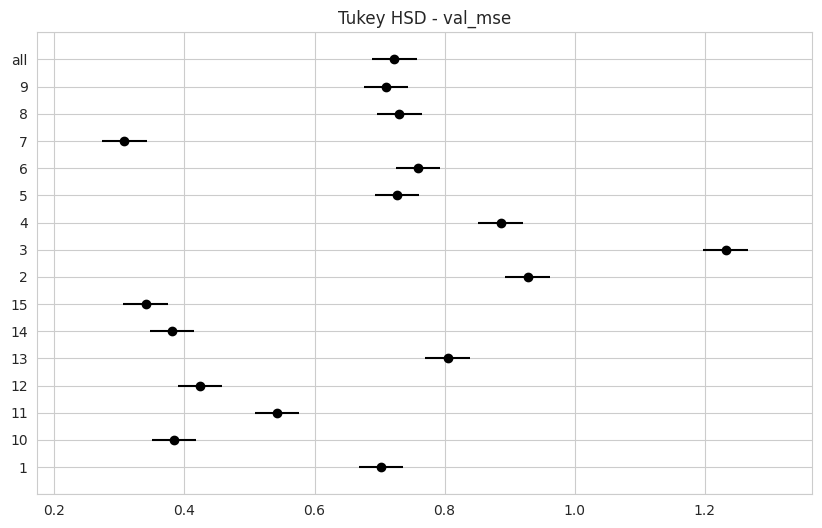


=== test_mse - Tukey HSD 检验 ===
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     1     10  -0.1883    0.0 -0.3032 -0.0734   True
     1     11  -0.3066    0.0 -0.4215 -0.1917   True
     1     12   -0.363    0.0 -0.4779 -0.2481   True
     1     13   0.1837    0.0  0.0688  0.2986   True
     1     14  -0.6727    0.0 -0.7876 -0.5578   True
     1     15  -0.5002    0.0 -0.6151 -0.3853   True
     1      2  -0.4466    0.0 -0.5615 -0.3317   True
     1      3   0.4033    0.0  0.2884  0.5182   True
     1      4  -0.2965    0.0 -0.4114 -0.1816   True
     1      5  -0.1961    0.0  -0.311 -0.0812   True
     1      6  -0.2901    0.0  -0.405 -0.1752   True
     1      7  -0.7168    0.0 -0.8317 -0.6019   True
     1      8    0.078 0.5399 -0.0369  0.1929  False
     1      9  -0.1483  0.002 -0.2632 -0.0334   True
     1    all  -0.1163 0.0446 -0.2311 -0.0014   True
    10     11

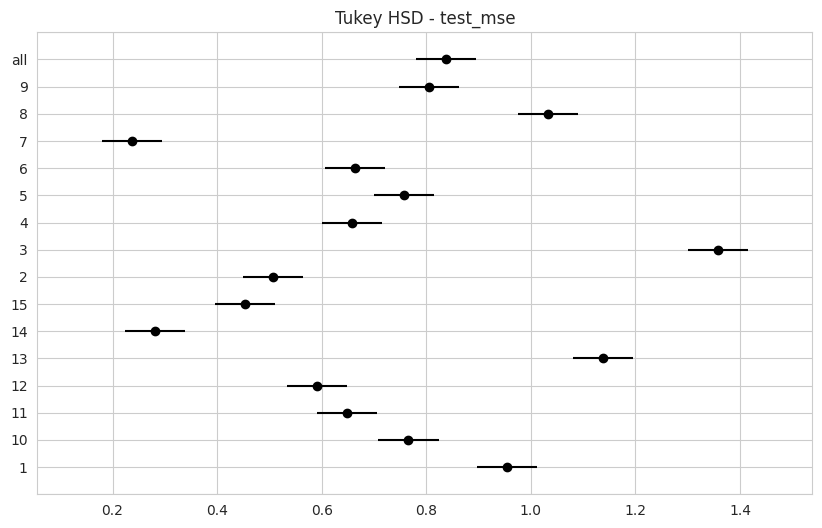

In [48]:
# Tukey HSD 事后检验
for metric in ['val_r2', 'test_r2', 'val_mse', 'test_mse']:
    if metric in cross_day_df.columns:
        data = cross_day_df.dropna(subset=[metric]).copy()
        data['subject_str'] = data['target_subject'].astype(str)
        
        tukey = pairwise_tukeyhsd(endog=data[metric], groups=data['subject_str'], alpha=0.05)
        
        print(f'\n=== {metric} - Tukey HSD 检验 ===')
        print(tukey.summary())
        
        # 可视化
        fig = tukey.plot_simultaneous()
        plt.title(f'Tukey HSD - {metric}')
        plt.show()

## 可视化对比

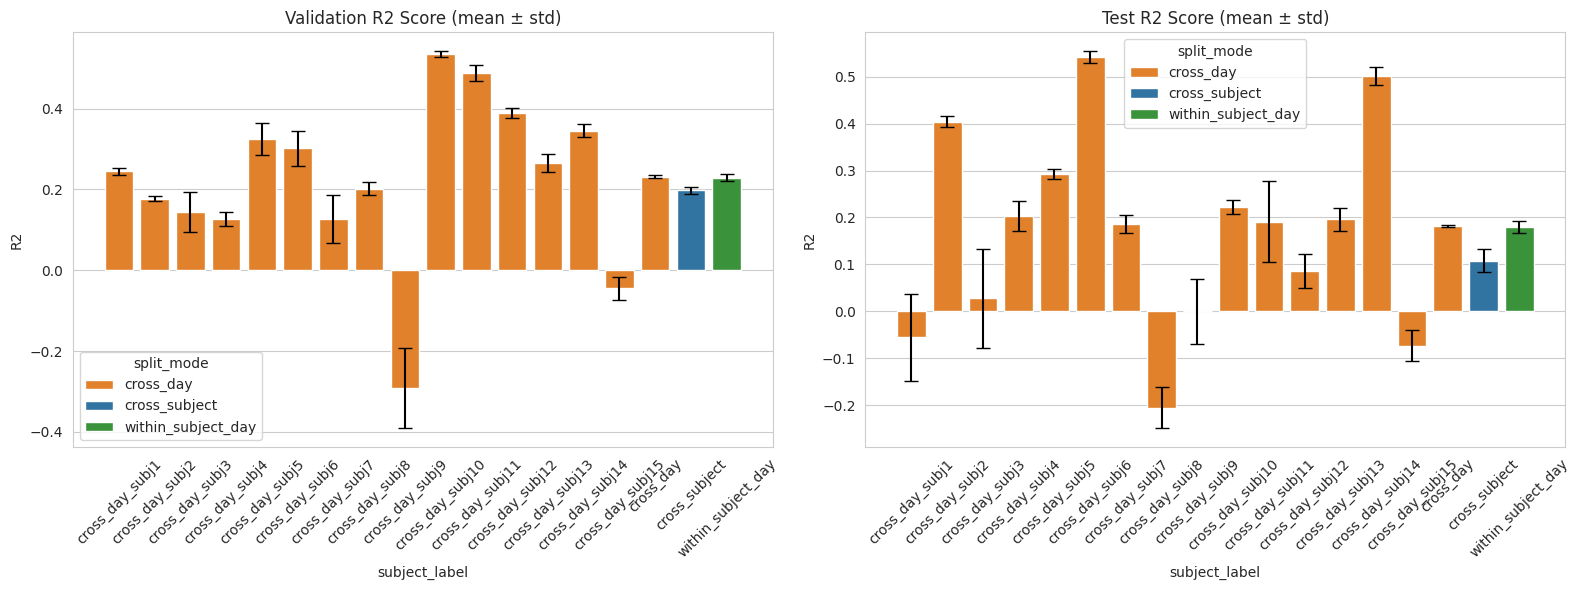

In [49]:
colors = {'cross_subject': '#1f77b4', 'cross_day': '#ff7f0e', 'within_subject_day': '#2ca02c'}

plot_data = summary_df.copy()
plot_data['subject_label'] = plot_data.apply(
    lambda row: f"{row['split_mode']}{'_subj' + str(row['target_subject']) if row['target_subject'] != 'all' else ''}",
    axis=1
)

plt.figure(figsize=(16, 6))

# Val R2
plt.subplot(1, 2, 1)
ax = sns.barplot(data=plot_data, x='subject_label', y='val_r2_mean', hue='split_mode', palette=colors)
for i, (_, row) in enumerate(plot_data.iterrows()):
    ax.errorbar(i, row['val_r2_mean'], yerr=row['val_r2_std'], fmt='none', c='black', capsize=5)
plt.title('Validation R2 Score (mean ± std)')
plt.xticks(rotation=45)
plt.ylabel('R2')

# Test R2
plt.subplot(1, 2, 2)
ax = sns.barplot(data=plot_data, x='subject_label', y='test_r2_mean', hue='split_mode', palette=colors)
for i, (_, row) in enumerate(plot_data.iterrows()):
    ax.errorbar(i, row['test_r2_mean'], yerr=row['test_r2_std'], fmt='none', c='black', capsize=5)
plt.title('Test R2 Score (mean ± std)')
plt.xticks(rotation=45)
plt.ylabel('R2')

plt.tight_layout()
plt.show()

## 原始实验记录列表

In [50]:
details_df = df[['timestamp', 'split_mode', 'target_subject', 'n_source_domains', 'best_epoch', 
                 'val_mse', 'val_mae', 'val_rmse', 'val_r2', 'val_pearson', 'val_spearman',
                 'test_mse', 'test_mae', 'test_rmse', 'test_r2', 'test_pearson', 'test_spearman',
                 'batch_size', 'n_epoch']]

details_df.style.format({
    'val_mse': '{:.6f}',
    'val_mae': '{:.6f}',
    'val_rmse': '{:.6f}',
    'val_r2': '{:.6f}',
    'val_pearson': '{:.6f}',
    'val_spearman': '{:.6f}',
    'test_mse': '{:.6f}',
    'test_mae': '{:.6f}',
    'test_rmse': '{:.6f}',
    'test_r2': '{:.6f}',
    'test_pearson': '{:.6f}',
    'test_spearman': '{:.6f}'
}).set_table_styles([{
    'selector': 'th',
    'props': [('font-size', '10px'), ('text-align', 'center')]
}, {
    'selector': 'td',
    'props': [('font-size', '10px'), ('text-align', 'center')]
}])

,timestamp,split_mode,target_subject,n_source_domains,best_epoch,val_mse,val_mae,val_rmse,val_r2,val_pearson,val_spearman,test_mse,test_mae,test_rmse,test_r2,test_pearson,test_spearman,batch_size,n_epoch
0,20260724_041801,cross_subject,all,9,327,0.974905,0.777564,0.987373,0.198304,-0.017656,-0.019103,0.699435,0.686861,0.836322,0.108430,0.054683,0.046923,256,351
1,20260724_061444,cross_day,1,6,130,0.711184,0.622554,0.843317,0.235313,0.050797,0.046090,0.910800,0.694956,0.954359,-0.007007,0.033671,0.038330,256,351
2,20260724_071121,within_subject_day,all,150,0,0.795973,0.689227,0.892173,0.239573,0.280162,0.302709,0.886409,0.723806,0.941493,0.185150,0.248707,0.277921,256,351
3,20260724_161802,cross_day,2,6,270,0.925640,0.586312,0.962102,0.178917,0.014355,0.003429,0.514444,0.438089,0.717247,0.396295,0.044374,0.045135,256,351
4,20260725_020320,cross_day,3,6,268,1.148709,0.860062,1.071778,0.202260,0.013596,0.011684,1.174133,0.840891,1.083574,0.159327,0.007728,-0.016964,256,351
5,20260725_163927,cross_day,4,6,111,0.877022,0.722652,0.936494,0.135034,0.129844,0.135379,0.701188,0.655291,0.837370,0.150175,-0.270694,-0.292627,256,351
6,20260726_031831,cross_day,5,6,118,0.723487,0.641373,0.850581,0.327550,-0.005622,-0.003823,0.751432,0.678193,0.866852,0.298702,0.070444,0.061499,256,351
7,20260726_045814,cross_day,6,6,108,0.828137,0.713623,0.910020,0.237837,0.027641,0.010841,0.687770,0.628717,0.829319,0.525966,0.114506,0.134799,256,351
8,20260726_054025,cross_day,7,6,228,0.295785,0.309130,0.543861,0.159607,0.067858,0.067488,0.234088,0.283531,0.483826,0.197395,-0.056978,-0.059547,256,351
9,20260726_063333,cross_day,8,6,166,0.743964,0.677962,0.862533,0.187589,-0.098158,-0.100002,1.049184,0.769863,1.024297,-0.225012,0.194223,0.185446,256,351
